# Comparación de modelos de minería de datos

Este notebook evalúa los modelos guardados en `models/` sobre el mismo conjunto de test cronológico (`data/test_data.npz`). El archivo conserva las particiones train/validación/test para reproducir los preprocesadores sin ajustar transformaciones con datos de test.

La etiqueta común es `hay_cola = pct_posible_cola > 0.5`. Debido a que los modelos secuenciales requieren historial previo y continuo, los resultados finales se calculan sobre la intersección exacta de filas de test para las que los cuatro modelos producen una predicción.

## Preparación específica por modelo

- **GRU y TCN:** ventanas de 48 bloques por robot, con objetivo en el bloque siguiente; se conservan solo ventanas con continuidad de 30 minutos. Se usa el scaler incluido para GRU. El artefacto de TCN no incluye scaler, así que se reconstruye ajustándolo únicamente con train.
- **LSTM:** ventanas cronológicas de 24 filas y codificación de robot/temporada como en su notebook de entrenamiento; el preprocesador se ajusta con train.
- **Regresión logística:** se recrean las variables de rezago, codificación cíclica y dummies de su notebook; el preprocesador también se ajusta con train.

Cada vector de predicciones conserva el índice de la fila objetivo original, lo que permite comparar los modelos exactamente sobre las mismas filas.

In [6]:
from setup import load_test_data, prepare_models, common_test_rows

data = load_test_data()
models, predictions = prepare_models(data)

Datos: 179,850 filas; train=125,894, validación=26,978, test=26,978
Test cronológico: 2025-06-27 15:30:00 -> 2025-12-31 23:30:00
Modelos disponibles: ['gru_E2_w48.keras', 'logistic_regresion.keras', 'lstm_model.keras', 'tcn_classification_base_w48.keras']


c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to

Variables de entrada: {'Regresión logística': 25, 'LSTM': (24, 29), 'GRU/TCN': (48, 27)}
Filas de test con predicción por modelo: {'GRU': 26978, 'TCN': 26978, 'LSTM': 26978, 'Regresión logística': 26978}


## Métricas y comparación

Los modelos se comparan solo en filas de test presentes en las cuatro salidas. Se interpreta el score de cada salida con un umbral de 0.5; para ROC-AUC y PR-AUC se usan los scores continuos. El GRU fue entrenado como regresor de `pct_posible_cola`, por lo que su salida se trata aquí como score de clasificación, no como una probabilidad calibrada.

Filas de test compartidas: 26,978 de 26,978


,Filas,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,,
LSTM,26978,0.6908,0.6577,0.9645,0.7821,0.7949,0.8200
TCN,26978,0.6721,0.6649,0.8670,0.7526,0.6961,0.7232
GRU,26978,0.6144,0.6913,0.5960,0.6401,0.6758,0.7066
Regresión logística,26978,0.4813,0.8325,0.1233,0.2147,0.7615,0.7715


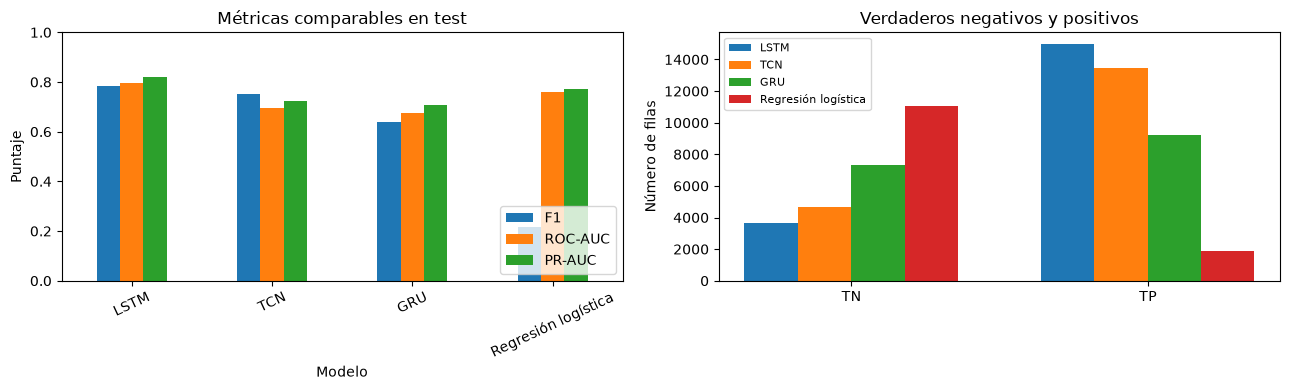

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
 
THRESHOLD = data.label_threshold
 
common_rows = common_test_rows(data, predictions)
actual = data.actual_labels(common_rows)
 
metrics = []
for model_name, scores in predictions.items():
    y_score = scores.loc[common_rows].to_numpy(dtype=float)
    y_pred = (y_score >= THRESHOLD).astype(np.int32)
    metrics.append({
        "Modelo": model_name,
        "Filas": len(common_rows),
        "Accuracy": accuracy_score(actual, y_pred),
        "Precision": precision_score(actual, y_pred, zero_division=0),
        "Recall": recall_score(actual, y_pred, zero_division=0),
        "F1": f1_score(actual, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, y_score),
        "PR-AUC": average_precision_score(actual, y_score),
    })
 
results = pd.DataFrame(metrics).set_index("Modelo").sort_values("F1", ascending=False)
print(f"Filas de test compartidas: {len(common_rows):,} de {len(data.test):,}")
display(results.round(4))
 
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results[["F1", "ROC-AUC", "PR-AUC"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Métricas comparables en test")
axes[0].set_ylabel("Puntaje")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(loc="lower right")
 
confusion_axes = axes[1]
width = 0.18
for offset, model_name in enumerate(results.index):
    y_score = predictions[model_name].loc[common_rows].to_numpy(dtype=float)
    y_pred = (y_score >= THRESHOLD).astype(np.int32)
    cm = confusion_matrix(actual, y_pred, labels=[0, 1]).ravel()
    x = np.arange(2) + (offset - (len(results.index) - 1) / 2) * width
    confusion_axes.bar(x, cm[[0, 3]], width=width, label=model_name)
confusion_axes.set_xticks([0, 1], ["TN", "TP"])
confusion_axes.set_title("Verdaderos negativos y positivos")
confusion_axes.set_ylabel("Número de filas")
confusion_axes.legend(fontsize=8)
plt.tight_layout()
plt.show()